# Lab 08 – Object Detection with R-CNN (Pedestrian Detection)

**Dataset:** Penn-Fudan Pedestrian dataset (170 street images, pedestrians annotated with instance masks → boxes). *Not* BCCD.

**Classic R-CNN pipeline implemented here**
1. Region proposals with **Selective Search**
2. Warp each proposal to 224×224 and extract CNN features (pretrained ResNet-18, frozen)
3. **Linear SVM** classifies each region (pedestrian vs. background)
4. **Bounding-box regression** (ridge) refines each box
5. **Non-Maximum Suppression**, then evaluation (AP@0.5) and visualisation

In [7]:
# Run once. Selective search lives in opencv-contrib (the plain opencv-python package does NOT have it).
# On Colab: Runtime > Change runtime type > T4 GPU (optional, speeds up feature extraction).
# Remove the preinstalled plain OpenCV first so the contrib build (with ximgproc) is the one imported.
!pip uninstall -y -q opencv-python opencv-python-headless opencv-contrib-python
!pip install -q opencv-contrib-python-headless scikit-learn matplotlib requests tqdm
# torch / torchvision are preinstalled on Colab. Locally also run: pip install torch torchvision

In [8]:
import os, glob, zipfile, io, random, pickle
import numpy as np, cv2, requests, torch, torchvision
import matplotlib.pyplot as plt
from PIL import Image
from tqdm import tqdm
from sklearn.svm import LinearSVC
from sklearn.linear_model import Ridge

SEED = 0
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
device = 'cuda' if torch.cuda.is_available() else 'cpu'
print('device:', device, '| has selective search:', hasattr(cv2, 'ximgproc'))

device: cuda | has selective search: True


## 1. Dataset: download and build ground-truth boxes

In [9]:
URL = 'https://www.cis.upenn.edu/~jshi/ped_html/PennFudanPed.zip'
if not os.path.exists('PennFudanPed'):
    r = requests.get(URL, timeout=120); r.raise_for_status()
    zipfile.ZipFile(io.BytesIO(r.content)).extractall('.')

img_paths  = sorted(glob.glob('PennFudanPed/PNGImages/*.png'))
mask_paths = sorted(glob.glob('PennFudanPed/PedMasks/*.png'))

def mask_to_boxes(mask_path):
    m = np.array(Image.open(mask_path))
    boxes = []
    for i in np.unique(m)[1:]:                       # 0 = background
        ys, xs = np.where(m == i)
        boxes.append([xs.min(), ys.min(), xs.max(), ys.max()])
    return np.array(boxes, dtype=np.float32)

images = [np.array(Image.open(p).convert('RGB')) for p in img_paths]
gts    = [mask_to_boxes(p) for p in mask_paths]
print(len(images), 'images,', sum(len(g) for g in gts), 'pedestrians')

# train / test split
idx = np.random.permutation(len(images))
test_idx, train_idx = idx[:30], idx[30:]
print('train:', len(train_idx), 'test:', len(test_idx))

170 images, 423 pedestrians
train: 140 test: 30


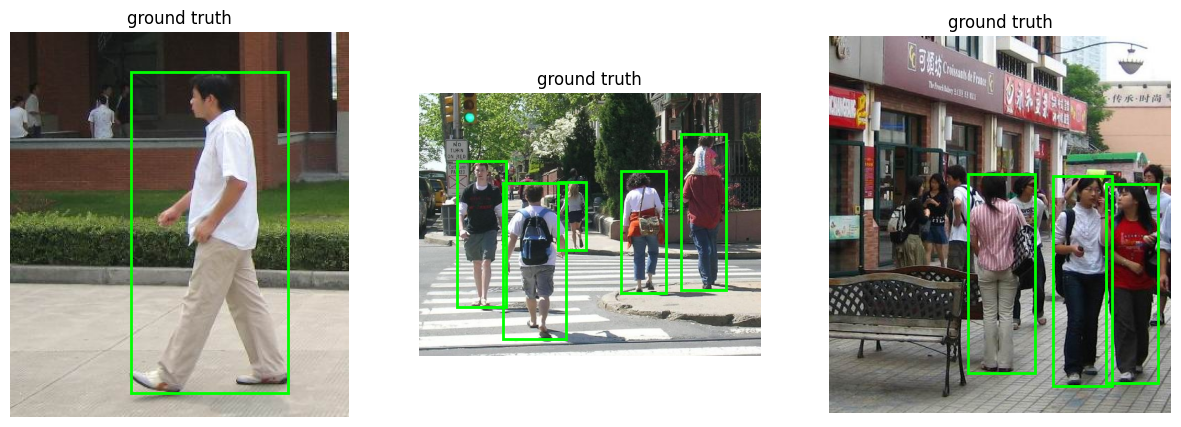

In [10]:
def show_boxes(img, boxes, color='lime', scores=None, ax=None, title=''):
    ax = ax or plt.gca()
    ax.imshow(img); ax.axis('off'); ax.set_title(title)
    for k, (x1, y1, x2, y2) in enumerate(boxes):
        ax.add_patch(plt.Rectangle((x1, y1), x2-x1, y2-y1, fill=False, edgecolor=color, linewidth=2))
        if scores is not None:
            ax.text(x1, y1-3, f'{scores[k]:.2f}', color='black', backgroundcolor=color, fontsize=8)

fig, axs = plt.subplots(1, 3, figsize=(15, 5))
for a, i in zip(axs, train_idx[:3]):
    show_boxes(images[i], gts[i], ax=a, title='ground truth')
plt.show()

## 2. Region proposals – Selective Search

proposals: 600
best IoU of proposals with each GT (recall check): [0.4]


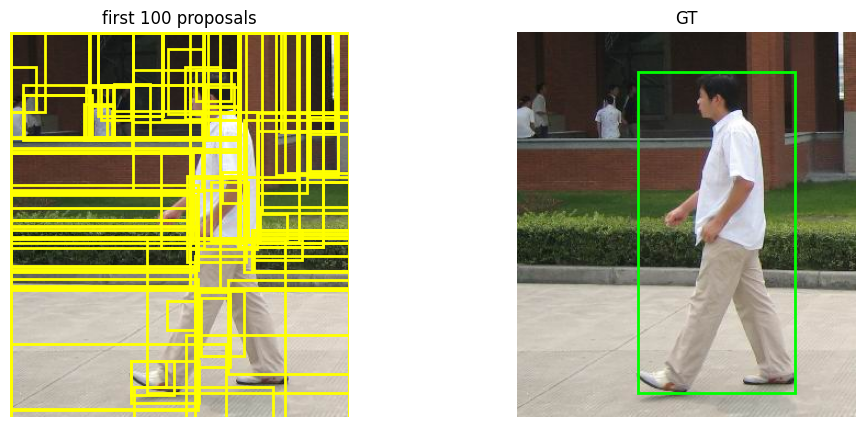

In [11]:
def iou_matrix(a, b):
    # a: (N,4), b: (M,4) in x1,y1,x2,y2 -> (N,M)
    ix1 = np.maximum(a[:, None, 0], b[None, :, 0]); iy1 = np.maximum(a[:, None, 1], b[None, :, 1])
    ix2 = np.minimum(a[:, None, 2], b[None, :, 2]); iy2 = np.minimum(a[:, None, 3], b[None, :, 3])
    inter = np.clip(ix2-ix1, 0, None) * np.clip(iy2-iy1, 0, None)
    area_a = (a[:, 2]-a[:, 0]) * (a[:, 3]-a[:, 1]); area_b = (b[:, 2]-b[:, 0]) * (b[:, 3]-b[:, 1])
    return inter / (area_a[:, None] + area_b[None, :] - inter + 1e-9)

def selective_search(img_rgb, max_props=600, work_size=320, min_side=20):
    h, w = img_rgb.shape[:2]
    s = work_size / max(h, w)                                   # downscale for speed
    small = cv2.cvtColor(cv2.resize(img_rgb, (int(w*s), int(h*s))), cv2.COLOR_RGB2BGR)
    ss = cv2.ximgproc.segmentation.createSelectiveSearchSegmentation()
    ss.setBaseImage(small); ss.switchToSelectiveSearchFast()
    r = ss.process().astype(np.float32) / s                     # x,y,w,h in original scale
    boxes = np.stack([r[:, 0], r[:, 1], r[:, 0]+r[:, 2], r[:, 1]+r[:, 3]], 1)
    keep = ((boxes[:, 2]-boxes[:, 0]) >= min_side) & ((boxes[:, 3]-boxes[:, 1]) >= min_side)
    return boxes[keep][:max_props]

props = selective_search(images[train_idx[0]])
print('proposals:', len(props))
fig, ax = plt.subplots(1, 2, figsize=(12, 5))
show_boxes(images[train_idx[0]], props[:100], color='yellow', ax=ax[0], title='first 100 proposals')
best = iou_matrix(gts[train_idx[0]], props).max(1)
print('best IoU of proposals with each GT (recall check):', best.round(2))
show_boxes(images[train_idx[0]], gts[train_idx[0]], ax=ax[1], title='GT'); plt.show()

In [6]:
# Compute (and cache) proposals for every image
if os.path.exists('proposals.pkl'):
    proposals = pickle.load(open('proposals.pkl', 'rb'))
else:
    proposals = [selective_search(im) for im in tqdm(images)]
    pickle.dump(proposals, open('proposals.pkl', 'wb'))

# proposal recall @ IoU 0.5 over the dataset
hit = tot = 0
for p, g in zip(proposals, gts):
    m = iou_matrix(g, p).max(1); hit += (m >= 0.5).sum(); tot += len(m)
print(f'Proposal recall @0.5: {hit/tot:.3f}')

100%|██████████| 170/170 [01:39<00:00,  1.71it/s]

Proposal recall @0.5: 0.835


## 3. CNN feature extractor (region warping → ResNet-18)

In [12]:
weights = torchvision.models.ResNet18_Weights.DEFAULT
backbone = torchvision.models.resnet18(weights=weights)
backbone.fc = torch.nn.Identity()                  # 512-d feature per region
backbone = backbone.eval().to(device)
MEAN = torch.tensor([0.485, 0.456, 0.406]).view(3, 1, 1); STD = torch.tensor([0.229, 0.224, 0.225]).view(3, 1, 1)
PAD = 16                                           # context pixels (as in the R-CNN paper)

def warp(img, box, size=224):
    h, w = img.shape[:2]
    x1, y1, x2, y2 = box
    x1, y1 = int(max(0, x1-PAD)), int(max(0, y1-PAD)); x2, y2 = int(min(w, x2+PAD)), int(min(h, y2+PAD))
    crop = cv2.resize(img[y1:max(y2, y1+1), x1:max(x2, x1+1)], (size, size))   # anisotropic warp
    t = torch.from_numpy(crop).permute(2, 0, 1).float() / 255.
    return (t - MEAN) / STD

@torch.no_grad()
def extract(img, boxes, bs=64):
    out = []
    for i in range(0, len(boxes), bs):
        x = torch.stack([warp(img, b) for b in boxes[i:i+bs]]).to(device)
        out.append(backbone(x).cpu().numpy())
    return np.concatenate(out) if out else np.zeros((0, 512), np.float32)

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 147MB/s]


## 4. Build the training set
For each training image: proposals with **IoU ≥ 0.5** to a GT are positives (plus the GT boxes themselves),
proposals with **IoU < 0.3** are negatives (sampled). Positives also store their matched GT for box regression.

In [13]:
POS_T, NEG_T = 0.5, 0.3
MAX_POS, MAX_NEG = 20, 40
feats, labels, pboxes, gboxes, ious = [], [], [], [], []

for i in tqdm(train_idx):
    img, g, p = images[i], gts[i], proposals[i]
    p = np.concatenate([p, g])                               # add GT boxes as proposals
    iou = iou_matrix(p, g); best = iou.max(1); arg = iou.argmax(1)
    pos = np.where(best >= POS_T)[0]; neg = np.where(best < NEG_T)[0]
    pos = np.random.permutation(pos)[:MAX_POS]; neg = np.random.permutation(neg)[:MAX_NEG]
    sel = np.concatenate([pos, neg])
    f = extract(img, p[sel])
    feats.append(f); labels.append(np.r_[np.ones(len(pos)), np.zeros(len(neg))])
    pboxes.append(p[sel]); gboxes.append(g[arg[sel]]); ious.append(best[sel])

X = np.concatenate(feats); y = np.concatenate(labels).astype(int)
P = np.concatenate(pboxes); G = np.concatenate(gboxes); IOU = np.concatenate(ious)
print('samples:', X.shape, '| positives:', y.sum(), '| negatives:', (y == 0).sum())

100%|██████████| 140/140 [00:30<00:00,  4.60it/s]

samples: (7237, 512) | positives: 1637 | negatives: 5600


## 5. Train the linear SVM and the bounding-box regressor

In [14]:
svm = LinearSVC(C=0.1, class_weight='balanced', max_iter=20000).fit(X, y)
print('SVM train accuracy:', svm.score(X, y))

def encode(Pb, Gb):
    pw, ph = Pb[:, 2]-Pb[:, 0], Pb[:, 3]-Pb[:, 1]; px, py = Pb[:, 0]+pw/2, Pb[:, 1]+ph/2
    gw, gh = Gb[:, 2]-Gb[:, 0], Gb[:, 3]-Gb[:, 1]; gx, gy = Gb[:, 0]+gw/2, Gb[:, 1]+gh/2
    return np.stack([(gx-px)/pw, (gy-py)/ph, np.log(gw/pw), np.log(gh/ph)], 1)

def decode(Pb, t):
    pw, ph = Pb[:, 2]-Pb[:, 0], Pb[:, 3]-Pb[:, 1]; px, py = Pb[:, 0]+pw/2, Pb[:, 1]+ph/2
    cx, cy = px + t[:, 0]*pw, py + t[:, 1]*ph; w, h = pw*np.exp(t[:, 2]), ph*np.exp(t[:, 3])
    return np.stack([cx-w/2, cy-h/2, cx+w/2, cy+h/2], 1)

m = (y == 1) & (IOU >= 0.6)                          # regress only from boxes that are close to a GT
reg = Ridge(alpha=1.0).fit(X[m], encode(P[m], G[m]))
print('regressor trained on', m.sum(), 'boxes')

SVM train accuracy: 0.9900511261572474
regressor trained on 894 boxes


## 6. Inference: SVM score → box regression → NMS

In [15]:
def detect(img, props, f, score_thr=0.0, nms_thr=0.3, use_reg=True):
    s = svm.decision_function(f)
    keep = s > score_thr
    boxes, s = props[keep], s[keep]
    if len(boxes) == 0:
        return np.zeros((0, 4)), np.zeros(0)
    if use_reg:
        boxes = decode(boxes, reg.predict(f[keep]))
    h, w = img.shape[:2]
    boxes[:, [0, 2]] = boxes[:, [0, 2]].clip(0, w-1); boxes[:, [1, 3]] = boxes[:, [1, 3]].clip(0, h-1)
    k = torchvision.ops.nms(torch.tensor(boxes, dtype=torch.float32), torch.tensor(s, dtype=torch.float32), nms_thr).numpy()
    return boxes[k], s[k]

# cache test-set features once (proposals are shared by all variants)
test_feats = {i: extract(images[i], proposals[i]) for i in tqdm(test_idx)}

100%|██████████| 30/30 [00:43<00:00,  1.45s/it]


## 7. Evaluation – Average Precision @ IoU 0.5

AP@0.5  without bbox regression: 0.401
AP@0.5  with bbox regression: 0.489


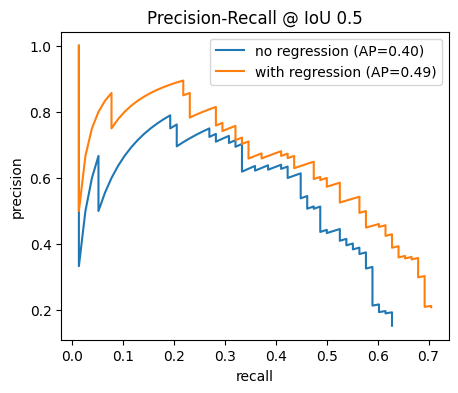

In [16]:
def voc_ap(dets, gt_dict, thr=0.5):
    npos = sum(len(g) for g in gt_dict.values())
    dets = sorted(dets, key=lambda d: -d[1])
    used = {k: np.zeros(len(v), bool) for k, v in gt_dict.items()}
    tp = np.zeros(len(dets)); fp = np.zeros(len(dets))
    for k, (i, sc, b) in enumerate(dets):
        ov = iou_matrix(b[None], gt_dict[i])[0]; j = ov.argmax()
        if ov[j] >= thr and not used[i][j]: tp[k] = 1; used[i][j] = True
        else: fp[k] = 1
    tp, fp = np.cumsum(tp), np.cumsum(fp)
    rec, prec = tp/npos, tp/np.maximum(tp+fp, 1e-9)
    mrec = np.r_[0, rec, 1]; mpre = np.r_[0, prec, 0]
    for k in range(len(mpre)-2, -1, -1): mpre[k] = max(mpre[k], mpre[k+1])
    ii = np.where(mrec[1:] != mrec[:-1])[0]
    return float(np.sum((mrec[ii+1]-mrec[ii]) * mpre[ii+1])), rec, prec

gt_test = {i: gts[i] for i in test_idx}
results = {}
for use_reg in (False, True):
    dets = []
    for i in test_idx:
        b, s = detect(images[i], proposals[i], test_feats[i], use_reg=use_reg)
        dets += [(i, sc, bb) for bb, sc in zip(b, s)]
    ap, rec, prec = voc_ap(dets, gt_test)
    results[use_reg] = (ap, rec, prec)
    print(f'AP@0.5  {"with" if use_reg else "without"} bbox regression: {ap:.3f}')

plt.figure(figsize=(5, 4))
for k, name in [(False, 'no regression'), (True, 'with regression')]:
    plt.plot(results[k][1], results[k][2], label=f'{name} (AP={results[k][0]:.2f})')
plt.xlabel('recall'); plt.ylabel('precision'); plt.legend(); plt.title('Precision-Recall @ IoU 0.5'); plt.show()

## 8. Visualise predictions on test images (green = prediction, red = ground truth)

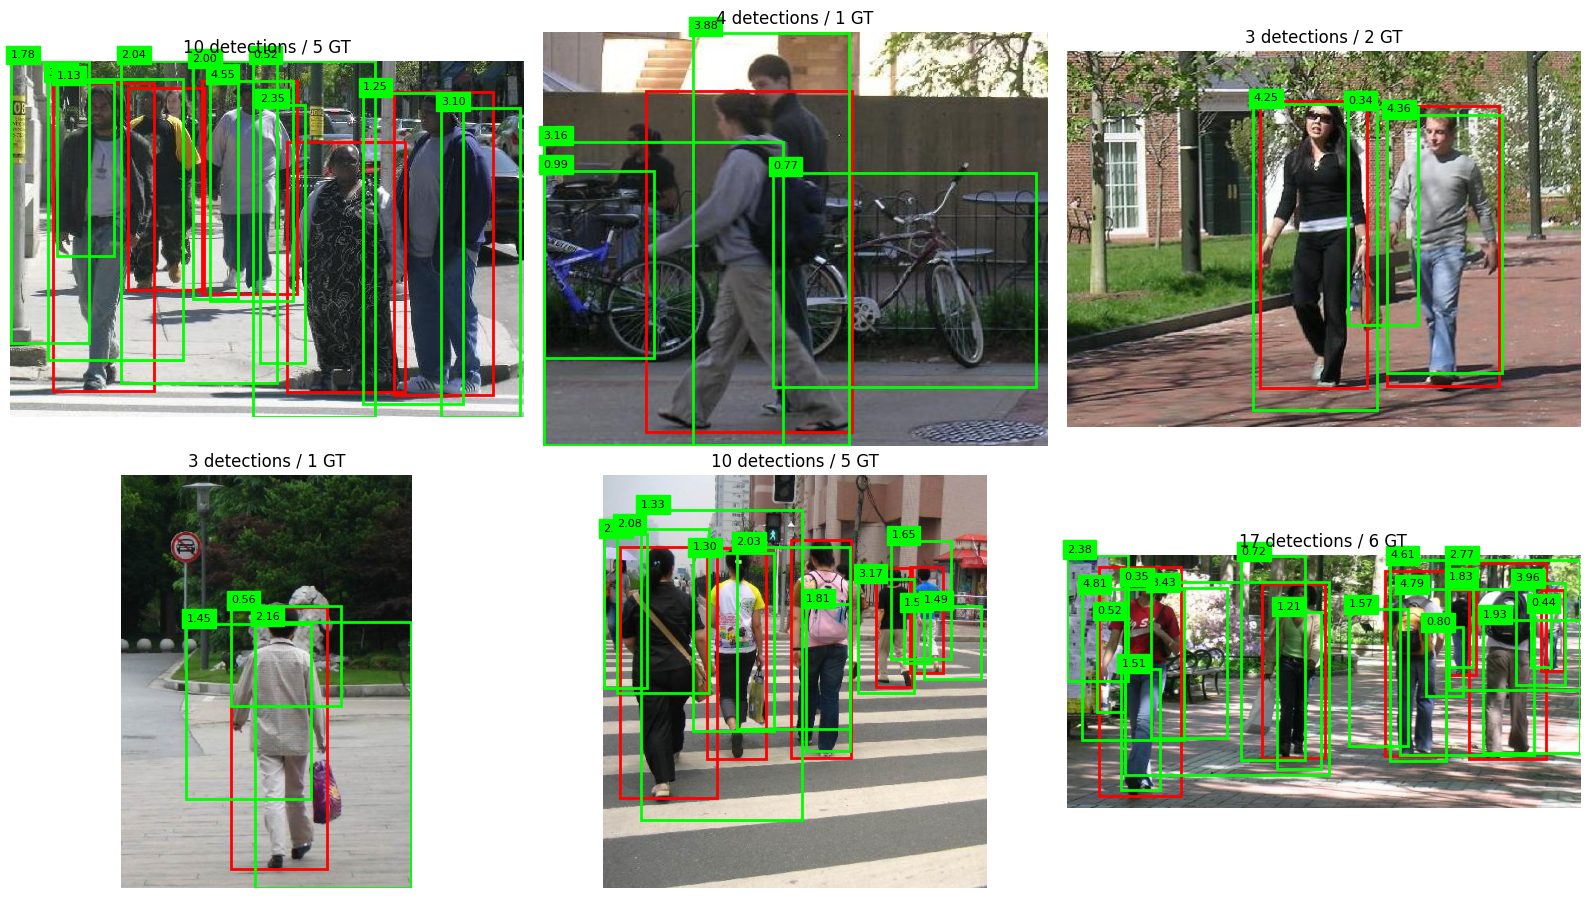

In [17]:
fig, axs = plt.subplots(2, 3, figsize=(16, 9))
for a, i in zip(axs.ravel(), test_idx[:6]):
    b, s = detect(images[i], proposals[i], test_feats[i], score_thr=0.3, use_reg=True)
    a.imshow(images[i]); a.axis('off')
    show_boxes(images[i], gts[i], color='red', ax=a)
    show_boxes(images[i], b, color='lime', scores=s, ax=a, title=f'{len(b)} detections / {len(gts[i])} GT')
plt.tight_layout(); plt.show()

## 9. Summary
* **R-CNN**: ~600 Selective-Search proposals per image → each *separately* warped and passed through the CNN (this is why it is slow: ~600 CNN forward passes per image) → SVM + box regressor.
* **Fast R-CNN** avoids this by running the CNN once per image and using RoI pooling; **Faster R-CNN** replaces Selective Search with an RPN.
* Here the CNN is a frozen ImageNet ResNet-18 (the original paper additionally fine-tunes the CNN on warped regions); results are reported with and without bounding-box regression.